# How much warmer is the FUT climate?

**Question.** How much warmer are the FUT simulations than PD? This notebook gives the number to quote, and shows where the warming sits.

**How the warming gets into the model.** The model atmosphere (CAM) runs on **prescribed SST and sea ice**, so the warming is mostly *imposed*, not simulated:

| | PD (`NF2000…`) | FUT (`NF2100ssp585…`) |
|---|---|---|
| SST / sea ice | NorESM2 NHIST climatology **1995–2005** | NorESM2 SSP5-8.5 climatology **2090–2100** |
| CO₂ and other forcing | year 2000 | SSP5-8.5, year 2100 |
| Winds | nudged to the **PD** met run (u, v, PS, 6 h) | same PD winds |

So over the ocean the FUT − PD difference comes from the SST files, set by construction. Over land the surface reacts to the warmer ocean and the higher CO₂. Both runs are nudged to the same PD winds, so the large-scale circulation cannot change. Year *y* of FUT has the same weather as year *y* of PD, which makes the yearly differences paired and low-noise.

**Runs.** CTRL_PD `-20261029` and CTRL_FUT `-20261028` (new spin-up chain, after the CO₂ fix), 2001–2014 (first 12 months dropped). The vegetation is the same in both: CTRL.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ARCHIVE = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')
CASES = {'PD': 'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029',
         'FUT': 'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028'}
YEARS = (2001, 2014)
SST_DIR = Path('/cluster/shared/noresm/inputdata/noresm-only/atm/cam/sst')
SST_FILES = {'PD': SST_DIR / 'fice-micom-divocn_sst-micom-dow_NHIST_f19_tn14_20190710_1995-2005_series_version20260209_clim.nc',
             'FUT': SST_DIR / 'fice-micom-divocn_sst-micom-dow_NSSP585frc2_f19_tn14_20191014_2090-2100_series_version20260209_clim.nc'}
MASK_FILE = Path('../check-simulation-equilibrium/lcc-modified-cells/modified_cells.nc')
OUT = Path('how_warmer_future_climate_is_outputs')
CACHE, FIG, TAB = OUT / 'cache', OUT / 'figures', OUT / 'tables'  # cache = regenerable monthly fields
for d in (CACHE, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
N_WORKERS = 8
VARS = ['TREFHT', 'TS', 'ICEFRAC', 'PRECT']  # PRECT = PRECC + PRECL, mm/day
R_EARTH = 6.371e6  # m

## 1. Monthly fields

Files are read with plain `netCDF4`, 8 at a time. Each month gets the year and month of its `time_bnds` midpoint. The monthly fields are cached in `cache/`.

In [2]:
def read_file(path):
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar == 'noleap', (path, t.calendar)
        b = d['time_bnds'][0].astype(float)
        date = netCDF4.num2date(b.mean(), t.units, t.calendar)
        get = lambda v: np.ma.filled(d[v][0].astype('f8'), np.nan)
        out = dict(year=date.year, month=date.month, days=b[1] - b[0], co2=float(d['co2vmr'][0]) * 1e6,
                   TREFHT=get('TREFHT'), TS=get('TS'), ICEFRAC=get('ICEFRAC'),
                   PRECT=(get('PRECC') + get('PRECL')) * 1e3 * 86400)
    return out

def load_monthly(period):
    case = CASES[period]
    f = CACHE / f'{case}_monthly_{YEARS[0]}-{YEARS[1]}.nc'
    if f.is_file() and not REBUILD_CACHE:
        return xr.open_dataset(f).load()
    files = sorted((ARCHIVE / case / 'atm/hist').glob(f'{case}.cam.h0.*.nc'))
    with ProcessPoolExecutor(N_WORKERS) as ex:
        recs = [r for r in ex.map(read_file, files) if YEARS[0] <= r['year'] <= YEARS[1]]
    assert len(recs) == 12 * (YEARS[1] - YEARS[0] + 1), (period, len(recs))
    with netCDF4.Dataset(files[0]) as d:
        lat, lon = d['lat'][:], d['lon'][:]
    coords = dict(lat=lat, lon=lon, year=('time', [r['year'] for r in recs]),
                  month=('time', [r['month'] for r in recs]), days=('time', [r['days'] for r in recs]),
                  co2=('time', [r['co2'] for r in recs]))
    ds = xr.Dataset({v: (('time', 'lat', 'lon'), np.stack([r[v] for r in recs])) for v in VARS}, coords=coords)
    ds.attrs['case'] = case
    ds.to_netcdf(f)
    return ds

MON = {p: load_monthly(p) for p in CASES}
with netCDF4.Dataset(next((ARCHIVE / CASES['PD'] / 'atm/hist').glob('*.cam.h0.*.nc'))) as d:
    gw = xr.DataArray(d['gw'][:], dims='lat', coords=dict(lat=MON['PD'].lat))
    LANDFRAC = xr.DataArray(d['LANDFRAC'][0], dims=('lat', 'lon'), coords=dict(lat=MON['PD'].lat, lon=MON['PD'].lon))
{p: (str(m.year.values[0]), str(m.year.values[-1]), m.sizes['time'], f'CO2 {float(m.co2.mean()):.0f} ppm') for p, m in MON.items()}

{'PD': ('2001', '2014', 168, 'CO2 369 ppm'),
 'FUT': ('2001', '2014', 168, 'CO2 1135 ppm')}

## 2. Annual and seasonal means, regions

Annual means are weighted by days per month. DJF uses Dec, Jan and Feb of the same year; the forcing is a repeating climatology, so this is fine. Area weights are `gw` × land or water fraction. "Water" means 1 − LANDFRAC, sea ice included.

In [3]:
SEASONS = {'ANN': range(1, 13), 'DJF': (12, 1, 2), 'JJA': (6, 7, 8)}

def yearly(m, season):
    sel = m.where(m.month.isin(list(SEASONS[season])), drop=True)
    w = sel.days
    return (sel * w).groupby('year').sum() / w.groupby('year').sum()

Y = {(p, s): yearly(MON[p][VARS], s) for p in CASES for s in SEASONS}

mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, LANDFRAC.lat) and np.allclose(mask.lon, LANDFRAC.lon)
mask = mask.assign_coords(lat=LANDFRAC.lat, lon=LANDFRAC.lon)
AREA = gw.broadcast_like(LANDFRAC)
LAT = LANDFRAC.lat.broadcast_like(LANDFRAC)
LAND, WATER = LANDFRAC, 1 - LANDFRAC
REGIONS = {
    'global': AREA,
    'global land': AREA * LAND,
    'global ocean': AREA * WATER,
    'NH': AREA * (LAT > 0),
    'SH': AREA * (LAT < 0),
    'tropics 30S-30N': AREA * (abs(LAT) <= 30),
    'Arctic >66.5N': AREA * (LAT > 66.5),
    'Arctic land >66.5N': AREA * LAND * (LAT > 66.5),
    'Arctic ocean >66.5N': AREA * WATER * (LAT > 66.5),
    'land 46-82N': AREA * LAND * ((LAT >= 46) & (LAT <= 82)),
    'LCC-modified cells': AREA * LAND * mask,
}

def regional(field, region):
    w = REGIONS[region]
    return (field * w).sum(('lat', 'lon')) / w.sum()

## 3. FUT − PD by region

`Δ` = mean of the 14 paired yearly differences (FUT year *y* − PD year *y*). `min`/`max` = range of these yearly differences, which shows how stable the number is.

In [4]:
rows = []
for v in ['TREFHT', 'TS', 'PRECT']:
    for s in SEASONS:
        if v != 'TREFHT' and s != 'ANN':
            continue
        for r in REGIONS:
            pd_, fu = regional(Y['PD', s][v], r), regional(Y['FUT', s][v], r)
            d = fu - pd_
            rows.append(dict(var=v, season=s, region=r, PD=float(pd_.mean()), FUT=float(fu.mean()),
                             delta=float(d.mean()), dmin=float(d.min()), dmax=float(d.max()),
                             pct=float(100 * d.mean() / pd_.mean()) if v == 'PRECT' else np.nan))
TABLE = pd.DataFrame(rows).set_index(['var', 'season', 'region'])
TABLE.to_csv(TAB / 'fut_minus_pd_by_region.csv')
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(TABLE.loc['TREFHT'].drop(columns='pct'))

PD    FUT  delta  dmin  dmax
season region                                              
ANN    global              287.74 291.22   3.48  3.45  3.50
       global land         282.34 287.28   4.94  4.84  5.00
       global ocean        289.99 292.86   2.87  2.86  2.88
       NH                  288.16 292.84   4.68  4.61  4.72
       SH                  287.32 289.60   2.28  2.27  2.29
       tropics 30S-30N     298.14 301.30   3.16  3.15  3.17
       Arctic >66.5N       258.96 267.82   8.87  8.43  9.14
       Arctic land >66.5N  258.02 266.08   8.06  7.67  8.30
       Arctic ocean >66.5N 259.57 268.96   9.39  8.88  9.75
       land 46-82N         269.76 276.38   6.62  6.34  6.83
       LCC-modified cells  266.24 273.70   7.46  7.09  7.73
DJF    global              285.91 289.60   3.69  3.61  3.74
       global land         276.78 282.11   5.32  5.11  5.46
       global ocean        289.70 292.71   3.01  2.98  3.03
       NH                  281.88 287.00   5.12  4.99  5.22
       SH                  289.93 292.19   2.26  2.24  2.27
       tropics 30S-30N     297.62 300.75   3.12  3.09  3.15
       Arctic >66.5N       243.84 257.40  13.56 12.99 14.33
       Arctic land >66.5N  241.21 251.82  10.61  9.89 11.22
       Arctic ocean >66.5N 245.55 261.04  15.49 15.01 16.36
       land 46-82N         253.97 261.92   7.94  7.47  8.32
       LCC-modified cells  248.69 258.48   9.78  9.15 10.31
JJA    global              289.53 293.01   3.48  3.45  3.50
       global land         287.66 292.75   5.09  4.98  5.16
       global ocean        290.31 293.12   2.81  2.80  2.83
       NH                  294.12 298.73   4.61  4.54  4.66
       SH                  284.94 287.29   2.35  2.32  2.37
       tropics 30S-30N     298.23 301.43   3.20  3.19  3.22
       Arctic >66.5N       274.35 278.93   4.58  4.41  4.76
       Arctic land >66.5N  275.16 281.65   6.49  6.15  6.93
       Arctic ocean >66.5N 273.82 277.16   3.34  3.23  3.47
       land 46-82N         284.87 291.70   6.83  6.50  7.02
       LCC-modified cells  282.60 289.68   7.08  6.72  7.29

In [5]:
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(TABLE.loc[['TS', 'PRECT']])

PD    FUT  delta  dmin  dmax    pct
var   season region                                                     
TS    ANN    global              288.92 292.34   3.42  3.39  3.45    NaN
             global land         283.00 288.09   5.09  4.97  5.14    NaN
             global ocean        291.37 294.11   2.73  2.72  2.75    NaN
             NH                  289.31 293.97   4.66  4.59  4.71    NaN
             SH                  288.52 290.71   2.19  2.18  2.20    NaN
             tropics 30S-30N     299.61 302.72   3.11  3.09  3.13    NaN
             Arctic >66.5N       259.06 268.16   9.10  8.67  9.38    NaN
             Arctic land >66.5N  257.44 265.80   8.35  7.98  8.60    NaN
             Arctic ocean >66.5N 260.11 269.70   9.59  9.08  9.95    NaN
             land 46-82N         269.82 276.61   6.79  6.52  7.00    NaN
             LCC-modified cells  266.24 273.86   7.62  7.26  7.88    NaN
PRECT ANN    global                2.81   2.89   0.09  0.07  0.09   3.04
             global land           2.14   2.24   0.10  0.06  0.13   4.73
             global ocean          3.08   3.16   0.08  0.07  0.10   2.56
             NH                    2.66   3.16   0.51  0.49  0.53  19.07
             SH                    2.96   2.62  -0.34 -0.36 -0.32 -11.35
             tropics 30S-30N       3.38   3.46   0.08  0.05  0.11   2.43
             Arctic >66.5N         0.99   1.30   0.31  0.28  0.33  30.98
             Arctic land >66.5N    0.99   1.31   0.32  0.28  0.35  32.13
             Arctic ocean >66.5N   0.99   1.30   0.30  0.27  0.33  30.23
             land 46-82N           1.50   1.84   0.34  0.31  0.38  22.63
             LCC-modified cells    1.48   1.93   0.44  0.41  0.49  29.77

In [6]:
dT = TABLE.loc['TREFHT'].loc['ANN', 'delta']
amp = pd.DataFrame({'ΔT (K)': dT, 'ratio to global': dT / dT['global']})
amp.to_csv(TAB / 'trefht_ann_amplification.csv')
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(amp)

,ΔT (K),ratio to global
region,,
global,3.48,1.00
global land,4.94,1.42
global ocean,2.87,0.83
NH,4.68,1.34
SH,2.28,0.66
tropics 30S-30N,3.16,0.91
Arctic >66.5N,8.87,2.55
Arctic land >66.5N,8.06,2.32
Arctic ocean >66.5N,9.39,2.70


## 4. Maps of ΔTREFHT

Grey contour = LCC-modified cells.

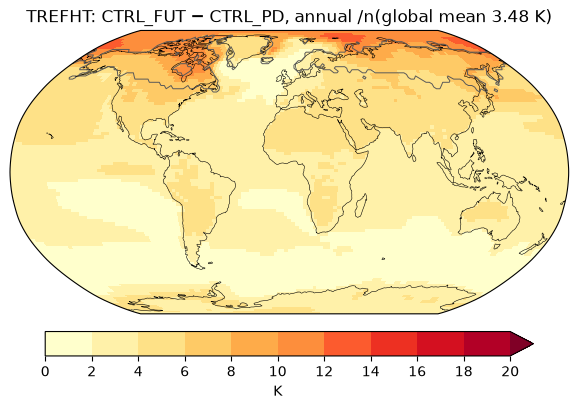

In [16]:
dmap = {s: Y['FUT', s].TREFHT.mean('year') - Y['PD', s].TREFHT.mean('year') for s in SEASONS}
LEVELS = np.arange(0, 22, 2)
NORM = mcolors.BoundaryNorm(LEVELS, plt.get_cmap('YlOrRd').N, extend='max')

def cyclic(da):
    return xr.concat([da, da.isel(lon=0).assign_coords(lon=360.)], 'lon')

def draw(ax, da):
    da = cyclic(da)
    im = ax.pcolormesh(da.lon, da.lat, da, cmap='YlOrRd', norm=NORM, transform=ccrs.PlateCarree(), shading='nearest')
    ax.contour(mask.lon, mask.lat, mask.astype(float), levels=[0.5], colors='0.35', linewidths=0.7, transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.4)
    return im

fig = plt.figure(figsize=(9, 4.6))
ax = fig.add_subplot(projection=ccrs.Robinson())
im = draw(ax, dmap['ANN'])
ax.set_title(f"TREFHT: CTRL_FUT − CTRL_PD, annual /n(global mean {dT['global']:.2f} K)")
fig.colorbar(im, ax=ax, orientation='horizontal', shrink=0.7, pad=0.05, ticks=LEVELS, label='K')
fig.savefig(FIG / 'dTREFHT_annual_global.png', dpi=200, bbox_inches='tight')
plt.show()

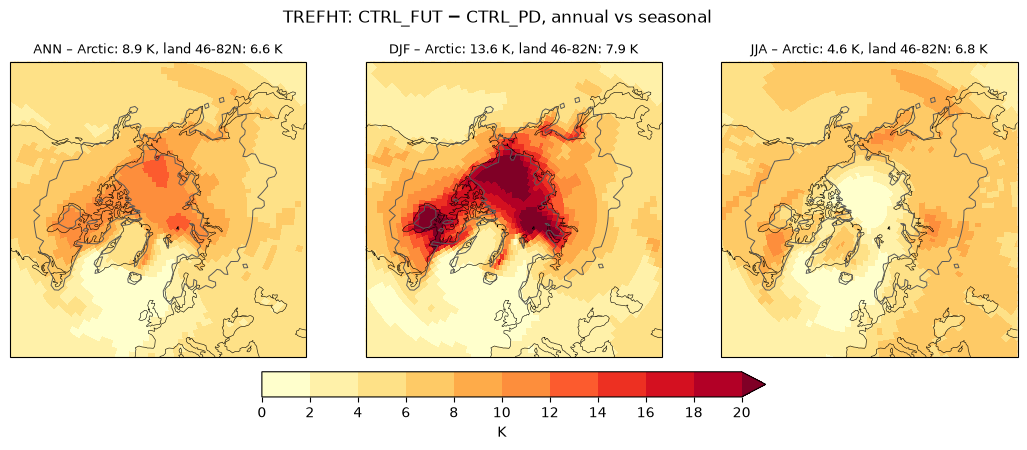

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.8), subplot_kw=dict(projection=ccrs.NorthPolarStereo()))
for ax, s in zip(axs, SEASONS):
    ax.set_extent([-180, 180, 40, 90], ccrs.PlateCarree())
    im = draw(ax, dmap[s])
    ax.set_title(f"{s} – Arctic: {TABLE.loc[('TREFHT', s, 'Arctic >66.5N'), 'delta']:.1f} K, "
                 f"land 46-82N: {TABLE.loc[('TREFHT', s, 'land 46-82N'), 'delta']:.1f} K", fontsize=9)
fig.colorbar(im, ax=axs, orientation='horizontal', shrink=0.5, pad=0.04, ticks=LEVELS, label='K')
plt.suptitle(f"TREFHT: CTRL_FUT − CTRL_PD, annual vs seasonal")
fig.savefig(FIG / 'dTREFHT_north_seasons.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. The prescribed ocean: SST and sea ice

This section reads the forcing files directly, so it shows what is imposed. It uses the `*_prediddle` fields, the true monthly means: `SST_cpl` (°C) and `ice_cov` (fraction) are adjusted so that CAM's linear time interpolation reproduces those means, so they are not means themselves. Ice-free = annual-mean ice < 15 %. Sea-ice area = Σ ice_cov × water fraction × cell area.

In [9]:
# *_prediddle = true monthly means; SST_cpl/ice_cov are adjusted mid-month values for time interpolation (can be < 0)
SST = {p: xr.open_dataset(f)[['SST_cpl_prediddle', 'ice_cov_prediddle']].load()
          .rename(SST_cpl_prediddle='SST_cpl', ice_cov_prediddle='ice_cov') for p, f in SST_FILES.items()}
assert np.allclose(SST['PD'].lat, LANDFRAC.lat) and np.allclose(SST['PD'].lon, LANDFRAC.lon)
for p in SST:
    SST[p] = SST[p].assign_coords(lat=LANDFRAC.lat, lon=LANDFRAC.lon, month=('time', np.arange(1, 13)))
CELL_AREA = 4 * np.pi * R_EARTH**2 * AREA / AREA.sum()  # m2
DAYS = xr.DataArray([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], dims='time')

def sst_mean(ds, region):
    w = REGIONS[region] * (ds.ice_cov.mean('time') < 0.15)  # ice-free (annual-mean ice < 15 %) water only
    ann = (ds.SST_cpl * DAYS).sum('time') / DAYS.sum()
    return float((ann * w).sum() / w.sum())

def ice_area(ds, hemi, month):
    sel = (LAT > 0) if hemi == 'NH' else (LAT < 0)
    return float((ds.ice_cov.isel(time=month - 1) * WATER * CELL_AREA * sel).sum()) / 1e12  # million km2

forc = pd.DataFrame({p: {
    'SST, ice-free ocean, global (°C)': sst_mean(SST[p], 'global ocean'),
    'SST, ice-free ocean, tropics (°C)': sst_mean(SST[p], 'tropics 30S-30N'),
    'SST, ice-free ocean, >46N (°C)': sst_mean(SST[p].where(SST[p].lat > 46), 'global ocean'),
    'NH sea ice, March (10^6 km2)': ice_area(SST[p], 'NH', 3),
    'NH sea ice, September (10^6 km2)': ice_area(SST[p], 'NH', 9),
    'SH sea ice, February (10^6 km2)': ice_area(SST[p], 'SH', 2),
    'SH sea ice, September (10^6 km2)': ice_area(SST[p], 'SH', 9),
    'CO2 (ppm)': float(MON[p].co2.mean()),
} for p in SST})
forc['FUT − PD'] = forc.FUT - forc.PD
forc.to_csv(TAB / 'prescribed_forcing.csv')
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(forc)

,PD,FUT,FUT − PD
"SST, ice-free ocean, global (°C)",20.52,22.68,2.16
"SST, ice-free ocean, tropics (°C)",21.37,23.51,2.14
"SST, ice-free ocean, >46N (°C)",7.91,9.62,1.71
"NH sea ice, March (10^6 km2)",13.78,10.77,-3.02
"NH sea ice, September (10^6 km2)",5.34,0.03,-5.31
"SH sea ice, February (10^6 km2)",1.41,1.00,-0.41
"SH sea ice, September (10^6 km2)",11.22,10.22,-1.01
CO2 (ppm),369.12,1135.20,766.08


**Check:** the model's ICEFRAC should match the prescribed ice_cov (NH September sea-ice area from the history files vs the forcing file).

In [10]:
for p in CASES:
    m = MON[p]
    sep = m.ICEFRAC.where(m.month == 9, drop=True).mean('time')
    print(p, f"model ICEFRAC NH Sep: {float((sep * CELL_AREA * (LAT > 0)).sum()) / 1e12:.2f} 10^6 km2;",
          f"forcing: {forc.loc['NH sea ice, September (10^6 km2)', p]:.2f}")

PD model ICEFRAC NH Sep: 5.34 10^6 km2; forcing: 5.34
FUT model ICEFRAC NH Sep: 0.03 10^6 km2; forcing: 0.03


## 6. Zonal means

Zonal-mean ΔTREFHT (annual, DJF, JJA) and the zonal-mean ΔSST of the forcing over ice-free ocean (both runs ice-free).

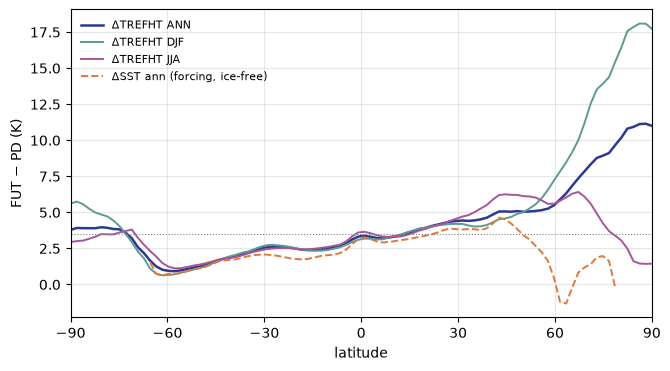

In [19]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
O = dict(gold='#EBC45C', orange='#DE7A3A', red='#BC423E', plum='#9A4A84', navy='#2C3990', teal='#5D9A92')
zm = lambda da, w: (da * w).sum('lon') / w.sum('lon')
fig, ax = plt.subplots(figsize=(7.5, 4))
for s, c in zip(SEASONS, [O['navy'], O['teal'], O['plum']]):
    ax.plot(LANDFRAC.lat, zm(dmap[s], AREA), c=c, lw=1.8 if s == 'ANN' else 1.4, label=f'ΔTREFHT {s}')
icefree = ((SST['PD'].ice_cov.max('time') < 0.15) & (SST['FUT'].ice_cov.max('time') < 0.15) & (WATER > 0.5))
dsst = ((SST['FUT'].SST_cpl - SST['PD'].SST_cpl) * DAYS).sum('time') / DAYS.sum()
ax.plot(LANDFRAC.lat, zm(dsst, icefree.astype(float)), c=O['orange'], ls='--', lw=1.4, label='ΔSST ann (forcing, ice-free)')
ax.axhline(dT['global'], c='0.5', lw=0.8, ls=':')
ax.set_xlabel('latitude'); ax.set_ylabel('FUT − PD (K)'); ax.set_xlim(-90, 90); ax.set_xticks(range(-90, 91, 30))
ax.legend(fontsize=8, frameon=False); ax.grid(alpha=0.3)
fig.savefig(FIG / 'zonal_mean_dT.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Year-to-year stability

Global and Arctic ΔTREFHT for each paired year. The forcing is a repeating climatology and the winds are the same, so the spread shows only the residual (non-nudged) variability.

In [12]:
yy = pd.DataFrame({r: (regional(Y['FUT', 'ANN'].TREFHT, r) - regional(Y['PD', 'ANN'].TREFHT, r)).to_series()
                   for r in ['global', 'global land', 'Arctic >66.5N', 'land 46-82N', 'LCC-modified cells']})
yy.to_csv(TAB / 'dTREFHT_yearly.csv')
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(yy.T)

year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
global,3.48,3.48,3.48,3.49,3.49,3.48,3.47,3.47,3.49,3.45,3.48,3.49,3.50,3.46
global land,4.95,4.95,4.96,4.94,4.95,4.93,4.92,4.93,4.96,4.84,4.96,4.98,5.00,4.91
Arctic >66.5N,8.81,8.97,8.94,8.98,9.14,8.88,8.72,8.43,9.11,8.63,8.84,9.05,8.98,8.66
land 46-82N,6.62,6.70,6.69,6.63,6.61,6.53,6.58,6.53,6.68,6.34,6.60,6.77,6.83,6.57
LCC-modified cells,7.43,7.54,7.60,7.48,7.52,7.40,7.34,7.31,7.54,7.09,7.41,7.68,7.73,7.33


## 8. Relative to pre-industrial

There is no pre-industrial run in this project, so FUT − PI is **estimated** from the coupled model that produced our SST files, NorESM2-LM (CMIP6, same f19 grid):

FUT − PI ≈ (our FUT − PD) + (NorESM2-LM PD − PI)

- **PI** = 1850–1900 (the IPCC AR6 pre-industrial reference). **PD** = 1995–2005, the years of our PD SST climatology. Both are from the CMIP6 `historical` runs, `tas` (= TREFHT).
- The CMIP6 files don't record the NorESM case names, so I can't tell which member made our PD SST file (`NHIST_f19_tn14_20190710`) (c). The PD − PI term is therefore the mean of the three historical members on NIRD (r1–r3, p1f1), and their range is shown.
- **Check 1:** the coupled FUT − PD (`ssp585` r1, 2090–2100, minus `historical` r1, 1995–2005) should be close to our FUT − PD, which was driven by SSTs from such a run.
- **Check 2:** absolute PD temperatures, coupled vs our CTRL_PD. A large offset would mean that our PD is not the coupled model's PD state, and the sum above would not hold.

In [13]:
CMIP = Path('/nird/datapeak/NS9034K/CMIP6')
HIST_MEMBERS = ['r1i1p1f1', 'r2i1p1f1', 'r3i1p1f1']
PERIODS = {'PI': (1850, 1900), 'PD': (1995, 2005), 'FUT': (2090, 2100)}

def cmip_tas(exp, member, y0, y1):
    mip = 'ScenarioMIP' if exp.startswith('ssp') else 'CMIP'
    files = sorted((CMIP / mip / 'NCC/NorESM2-LM' / exp / member / 'Amon/tas/gn/latest').glob('*.nc'))
    files = [f for f in files if int(f.stem[-13:-9]) <= y1 and int(f.stem[-6:-2]) >= y0]  # …_gn_YYYYMM-YYYYMM
    with xr.open_mfdataset(files, decode_times=xr.coders.CFDatetimeCoder(use_cftime=True),
                           data_vars='minimal', coords='minimal', compat='override') as ds:
        tas = ds.tas.sel(time=slice(f'{y0}-01-01', f'{y1}-12-31')).load()
    assert tas.sizes['time'] == 12 * (y1 - y0 + 1) and tas.time.dt.calendar == 'noleap', (exp, member)
    assert np.allclose(tas.lat, LANDFRAC.lat) and np.allclose(tas.lon, LANDFRAC.lon)
    days = tas.time.dt.days_in_month
    return ((tas * days).sum('time') / days.sum()).assign_coords(lat=LANDFRAC.lat, lon=LANDFRAC.lon)

CPL = {(p, m): cmip_tas('historical', m, *PERIODS[p]) for m in HIST_MEMBERS for p in ('PI', 'PD')}
CPL['FUT', 'r1i1p1f1'] = cmip_tas('ssp585', 'r1i1p1f1', *PERIODS['FUT'])

rows = []
for r in ['global', 'global land', 'global ocean', 'Arctic >66.5N', 'land 46-82N', 'LCC-modified cells']:
    pdpi = [float(regional(CPL['PD', m] - CPL['PI', m], r)) for m in HIST_MEMBERS]
    ours = TABLE.loc[('TREFHT', 'ANN', r)]
    rows.append({'region': r,
                 'cpl PD−PI (r1–r3 mean)': np.mean(pdpi), 'cpl PD−PI min': min(pdpi), 'cpl PD−PI max': max(pdpi),
                 'cpl FUT−PD (r1)': float(regional(CPL['FUT', 'r1i1p1f1'] - CPL['PD', 'r1i1p1f1'], r)),
                 'ours FUT−PD': ours.delta,
                 'cpl FUT−PI (r1)': float(regional(CPL['FUT', 'r1i1p1f1'] - CPL['PI', 'r1i1p1f1'], r)),
                 'ours FUT−PI (estimate)': ours.delta + np.mean(pdpi),
                 'cpl PD abs (r1–r3, K)': np.mean([float(regional(CPL['PD', m], r)) for m in HIST_MEMBERS]),
                 'ours PD abs (K)': ours.PD})
PI_TABLE = pd.DataFrame(rows).set_index('region')
PI_TABLE.to_csv(TAB / 'fut_minus_pi_estimate.csv')
with pd.option_context('display.float_format', '{:.2f}'.format, 'display.width', 250):
    display(PI_TABLE.T)

region,global,global land,global ocean,Arctic >66.5N,land 46-82N,LCC-modified cells
cpl PD−PI (r1–r3 mean),0.40,0.52,0.35,1.63,0.71,0.94
cpl PD−PI min,0.37,0.46,0.31,1.39,0.54,0.76
cpl PD−PI max,0.45,0.59,0.40,1.90,0.85,1.10
cpl FUT−PD (r1),3.46,5.07,2.79,7.37,6.51,6.96
ours FUT−PD,3.48,4.94,2.87,8.87,6.62,7.46
cpl FUT−PI (r1),3.91,5.66,3.19,9.28,7.36,8.06
ours FUT−PI (estimate),3.88,5.46,3.22,10.50,7.33,8.39
"cpl PD abs (r1–r3, K)",288.11,283.09,290.20,262.58,271.62,268.71
ours PD abs (K),287.74,282.34,289.99,258.96,269.76,266.24


## 9. Answer

In [14]:
t = TABLE.loc['TREFHT']
f = lambda s, r: t.loc[(s, r), 'delta']
print(f"FUT is {f('ANN', 'global'):.1f} K warmer than PD in global, annual-mean 2-m air temperature "
      f"(land {f('ANN', 'global land'):.1f} K, ocean {f('ANN', 'global ocean'):.1f} K; "
      f"yearly range {t.loc[('ANN', 'global'), 'dmin']:.2f}-{t.loc[('ANN', 'global'), 'dmax']:.2f} K).")
print(f"Arctic (>66.5N) {f('ANN', 'Arctic >66.5N'):.1f} K annual ({f('ANN', 'Arctic >66.5N') / f('ANN', 'global'):.1f}x global), "
      f"{f('DJF', 'Arctic >66.5N'):.1f} K in DJF, {f('JJA', 'Arctic >66.5N'):.1f} K in JJA.")
print(f"Land 46-82N {f('ANN', 'land 46-82N'):.1f} K; LCC-modified cells {f('ANN', 'LCC-modified cells'):.1f} K "
      f"(DJF {f('DJF', 'LCC-modified cells'):.1f}, JJA {f('JJA', 'LCC-modified cells'):.1f}).")
print(f"Imposed: ice-free SST +{forc.loc['SST, ice-free ocean, global (°C)', 'FUT − PD']:.1f} K, "
      f"CO2 {forc.loc['CO2 (ppm)', 'PD']:.0f} -> {forc.loc['CO2 (ppm)', 'FUT']:.0f} ppm, "
      f"NH September sea ice {forc.loc['NH sea ice, September (10^6 km2)', 'PD']:.1f} -> {forc.loc['NH sea ice, September (10^6 km2)', 'FUT']:.1f} million km2.")
g = PI_TABLE.loc['global']
print(f"Relative to pre-industrial (1850-1900, estimate): FUT {g['ours FUT−PI (estimate)']:.1f} K warmer globally "
      f"(= {g['ours FUT−PD']:.2f} + NorESM2-LM PD-PI {g['cpl PD−PI (r1–r3 mean)']:.2f} K, members {g['cpl PD−PI min']:.2f}-{g['cpl PD−PI max']:.2f}); "
      f"Arctic {PI_TABLE.loc['Arctic >66.5N', 'ours FUT−PI (estimate)']:.1f} K, LCC cells {PI_TABLE.loc['LCC-modified cells', 'ours FUT−PI (estimate)']:.1f} K.")

FUT is 3.5 K warmer than PD in global, annual-mean 2-m air temperature (land 4.9 K, ocean 2.9 K; yearly range 3.45-3.50 K).
Arctic (>66.5N) 8.9 K annual (2.5x global), 13.6 K in DJF, 4.6 K in JJA.
Land 46-82N 6.6 K; LCC-modified cells 7.5 K (DJF 9.8, JJA 7.1).
Imposed: ice-free SST +2.2 K, CO2 369 -> 1135 ppm, NH September sea ice 5.3 -> 0.0 million km2.
Relative to pre-industrial (1850-1900, estimate): FUT 3.9 K warmer globally (= 3.48 + NorESM2-LM PD-PI 0.40 K, members 0.37-0.45); Arctic 10.5 K, LCC cells 8.4 K.


**In words (2026-11-03; CTRL_PD `-20261029`, CTRL_FUT `-20261028`, 2001–2014, TREFHT, annual; numbers from the cells above):**

| Region | FUT − PD | FUT − PI (estimate) |
|---|---|---|
| Global | **+3.5 K** | **+3.9 K** |
| Global land / ocean | +4.9 / +2.9 | +5.5 / +3.2 |
| Arctic >66.5°N | +8.9 (DJF +13.6, JJA +4.6) | +10.5 (coupled model directly: +9.3) |
| Land 46–82°N | +6.6 | +7.3 |
| LCC-modified cells | +7.5 (DJF +9.8, JJA +7.1) | +8.4 |

- FUT − PD is measured (a). The 14 paired years give 3.45–3.50 K globally.
- **What drives it:** ice-free SST +2.2 K, CO₂ 369 → 1135 ppm, NH September sea ice 5.3 → 0.0 million km². These are imposed by the SSP5-8.5 2090–2100 SST/sea-ice file, and the winds are nudged to PD (a).
- **FUT − PI = our FUT − PD + NorESM2-LM's own PD − PI** (historical r1–r3, 1995–2005 minus 1850–1900: +0.40 K global, members 0.37–0.45) (a for the terms, b for adding them).
  - **Global check:** the coupled run gives FUT − PD = 3.46 K (ours 3.48) and FUT − PI = 3.91 K (our estimate 3.88). Our runs reproduce the coupled model's global warming (a).
  - **Arctic:** our FUT − PD (+8.9) is larger than the coupled one (+7.4), and our PD Arctic is 3.6 K colder than the coupled PD. So the Arctic FUT − PI estimate (+10.5) is less reliable than the global one. The coupled model's own value is +9.3 K (b).
- NorESM2-LM warms only ~0.4 K from 1850–1900 to 1995–2005. That is less than observed (IPCC AR6: ≈ 0.85 K for 1995–2014; 1995–2005 somewhat less). With the observed PI→PD warming instead, FUT − PI would be ≈ 4.2 K globally (b; the AR6 value is from the literature, not computed here (c)).